Loading the Libraries

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('default')
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from scipy.signal import periodogram
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error


Loading the Data

In [2]:
from google.colab import files

uploaded = files.upload()

In [4]:
df2022 = pd.read_csv("/content/yankees_2022.csv")
df2023 = pd.read_csv("/content/yankees_2023.csv")
df2024 = pd.read_csv("/content/yankees_2024.csv")
df2025 = pd.read_csv("/content/yankees_2025.csv")

In [5]:
print(df2022.columns)

Index(['Gm#', 'Date', 'Unnamed: 2', 'Tm', 'Unnamed: 4', 'Opp', 'W/L', 'R',
       'RA', 'Inn', 'W-L', 'Rank', 'GB', 'Win', 'Loss', 'Save', 'Time', 'D/N',
       'Attendance', 'cLI', 'Streak', 'Orig. Scheduled'],
      dtype='object')


In [6]:
df2022.head()

,Gm#,Date,Unnamed: 2,Tm,Unnamed: 4,Opp,W/L,R,RA,Inn,...,GB,Win,Loss,Save,Time,D/N,Attendance,cLI,Streak,Orig. Scheduled
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.0,Friday Apr 8,boxscore,NYY,NaN,BOS,W-wo,6.0,5.0,11.0,...,Tied,King,Crawford,NaN,3:56,D,46097.0,0.98,+,NaN
2,2.0,Saturday Apr 9,boxscore,NYY,NaN,BOS,W,4.0,2.0,NaN,...,Tied,Luetge,Pivetta,Chapman,2:58,D,46882.0,1.01,++,NaN
3,3.0,Sunday Apr 10,boxscore,NYY,NaN,BOS,L,3.0,4.0,NaN,...,1.0,Crawford,Schmidt,Diekman,3:40,N,40108.0,1.02,-,NaN
4,4.0,Monday Apr 11,boxscore,NYY,NaN,TOR,L,0.0,3.0,NaN,...,1.0,Manoah,Taillon,Romano,3:03,N,26211.0,1.04,--,NaN


Data Cleaning Pipeline

In [7]:
def clean_yankees_season(df, season):
    df = df.dropna(how="all").copy()

    # keep home games only
    df_home = df[df["Unnamed: 4"].isna()].copy()

    # clean attendance
    df_home["Attendance"] = pd.to_numeric(df_home["Attendance"], errors="coerce")
    df_home = df_home.dropna(subset=["Attendance"])
    df_home["Attendance"] = df_home["Attendance"].astype(int)

    # remove doubleheader marker like "(2)"
    df_home["Date"] = (
        df_home["Date"]
        .astype(str)
        .str.replace(r"\s\(\d+\)", "", regex=True)
    )

    # add year and convert date
    df_home["Date"] = pd.to_datetime(
        df_home["Date"] + f" {season}",
        format="%A %b %d %Y"
    )

    # features
    df_home["DayOfWeek"] = df_home["Date"].dt.day_name()
    df_home["Season"] = season

    # keep only needed columns
    df_home = df_home[["Date", "Attendance", "DayOfWeek", "Season"]]


    # reset index
    df_home = df_home.reset_index(drop=True)

    return df_home

In [8]:
df2022_home = clean_yankees_season(df2022, 2022)
df2023_home = clean_yankees_season(df2023, 2023)
df2024_home = clean_yankees_season(df2024, 2024)
df2025_home = clean_yankees_season(df2025, 2025)

In [9]:
print("2022:", len(df2022_home))
print("2023:", len(df2023_home))
print("2024:", len(df2024_home))
print("2025:", len(df2025_home))

2022: 78
2023: 80
2024: 79
2025: 80


In [10]:
yankees_df = pd.concat(
    [df2022_home, df2023_home, df2024_home, df2025_home],
    ignore_index=True
)

yankees_df["t"] = np.arange(1, len(yankees_df) + 1)

In [11]:
yankees_df.head()

,Date,Attendance,DayOfWeek,Season,t
0,2022-04-08,46097,Friday,2022,1
1,2022-04-09,46882,Saturday,2022,2
2,2022-04-10,40108,Sunday,2022,3
3,2022-04-11,26211,Monday,2022,4
4,2022-04-12,25068,Tuesday,2022,5


In [12]:
yankees_df.tail(15)

,Date,Attendance,DayOfWeek,Season,t
302,2025-08-25,36939,Monday,2025,303
303,2025-08-26,35531,Tuesday,2025,304
304,2025-08-27,35501,Wednesday,2025,305
305,2025-09-05,46055,Friday,2025,306
306,2025-09-06,45123,Saturday,2025,307
307,2025-09-07,43266,Sunday,2025,308
308,2025-09-09,35653,Tuesday,2025,309
309,2025-09-10,36727,Wednesday,2025,310
310,2025-09-11,40608,Thursday,2025,311
311,2025-09-23,38318,Tuesday,2025,312


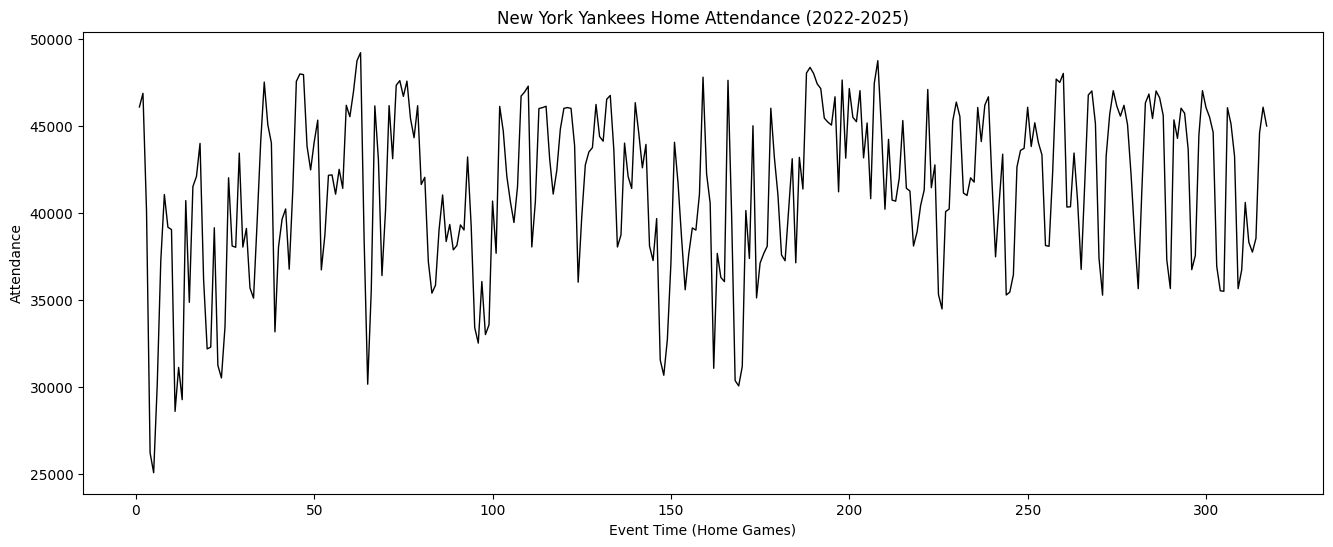

In [13]:
plt.figure(figsize=(16,6))

plt.plot(
    yankees_df["t"],
    yankees_df["Attendance"],
    color="black",
    linewidth=1
)
plt.title("New York Yankees Home Attendance (2022-2025)")
plt.xlabel("Event Time (Home Games)")
plt.ylabel("Attendance")

plt.show()

Split the dataset

In [14]:
train_df = yankees_df[yankees_df["Season"] != 2025].copy()
test_df  = yankees_df[yankees_df["Season"] == 2025].copy()

train_ts = train_df["Attendance"].values
test_ts = test_df["Attendance"].values

In [15]:
print(len(train_ts))
print(len(test_ts))

237
80


Plot ACF and PACF

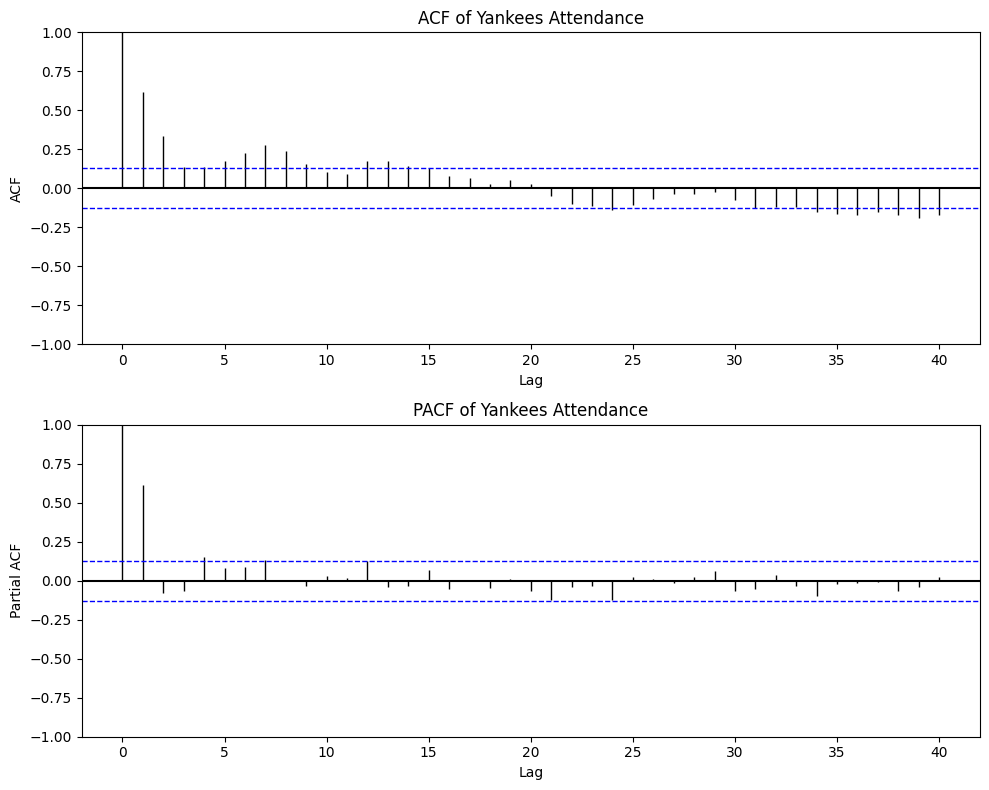

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(10,8))

# approximate confidence interval
conf = 1.96 / np.sqrt(len(train_ts))

# ACF
plot_acf(
    train_ts,
    lags=40,
    ax=axes[0],
    alpha=None,
    color="black",
    vlines_kwargs={"colors":"black","linewidth":1},
    marker=""
)

axes[0].axhline(conf, linestyle='--', color='blue', linewidth=1)
axes[0].axhline(-conf, linestyle='--', color='blue', linewidth=1)

axes[0].set_title("ACF of Yankees Attendance")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("ACF")

# PACF
plot_pacf(
    train_ts,
    lags=40,
    method='ywm',
    ax=axes[1],
    alpha=None,
    color="black",
    vlines_kwargs={"colors":"black","linewidth":1},
    marker=""
)

axes[1].axhline(conf, linestyle='--', color='blue', linewidth=1)
axes[1].axhline(-conf, linestyle='--', color='blue', linewidth=1)

axes[1].set_title("PACF of Yankees Attendance")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Partial ACF")

plt.tight_layout()
plt.show()

Periodogram

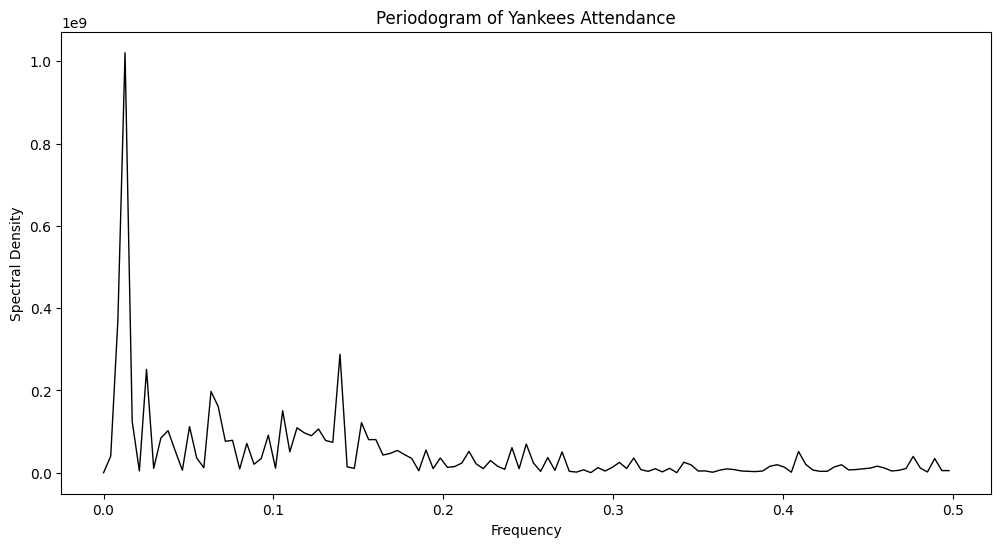

In [17]:

freqs, power = periodogram(train_ts)

plt.figure(figsize=(12,6))

plt.plot(
    freqs,
    power,
    color="black",
    linewidth=1
)

plt.title("Periodogram of Yankees Attendance")
plt.xlabel("Frequency")
plt.ylabel("Spectral Density")

plt.show()

# Phase 2: Deterministic Decomposition

In [18]:
# LOWESS trend fit
lowess_fit = lowess(
    endog=train_df["Attendance"],
    exog=train_df["t"],
    frac=0.15
)

# extract fitted trend values
trend = lowess_fit[:, 1]

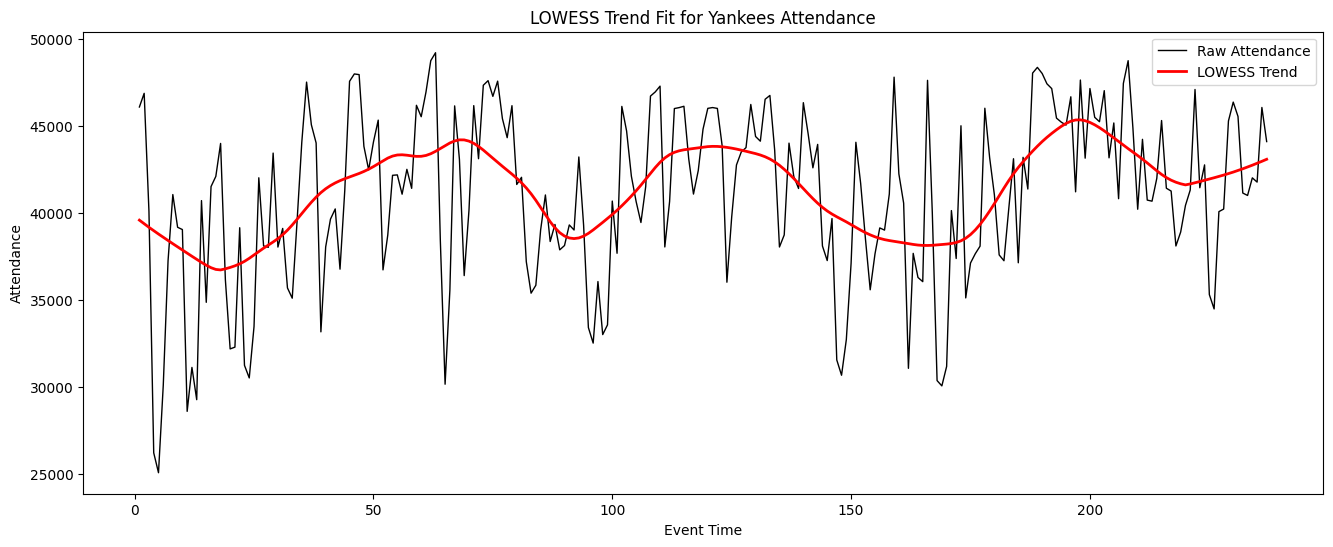

In [19]:
plt.figure(figsize=(16,6))

# raw series
plt.plot(
    train_df["t"],
    train_df["Attendance"],
    color="black",
    linewidth=1,
    label="Raw Attendance"
)

# smooth trend
plt.plot(
    train_df["t"],
    trend,
    color="red",
    linewidth=2,
    label="LOWESS Trend"
)

plt.title("LOWESS Trend Fit for Yankees Attendance")
plt.xlabel("Event Time")
plt.ylabel("Attendance")

plt.legend()

plt.show()

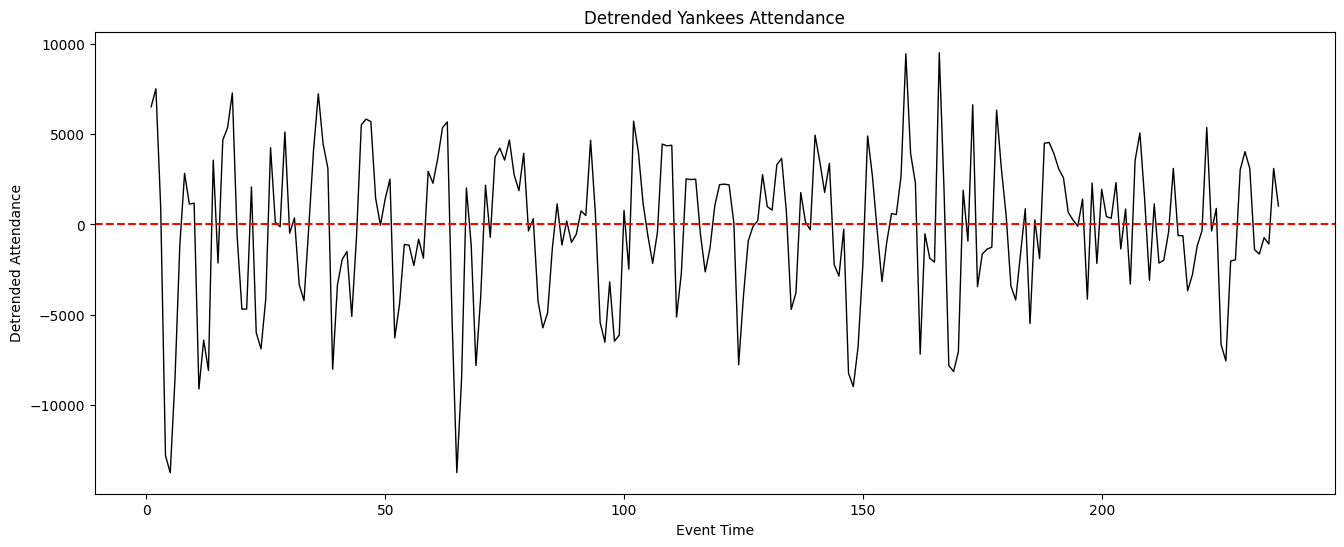

In [20]:
train_df["Detrended"] = (
    train_df["Attendance"] - trend
)
plt.figure(figsize=(16,6))

plt.plot(
    train_df["t"],
    train_df["Detrended"],
    color="black",
    linewidth=1
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Detrended Yankees Attendance")
plt.xlabel("Event Time")
plt.ylabel("Detrended Attendance")

plt.show()

Weekly Cycle Removal

In [21]:
weekday_means = (
    train_df
    .groupby("DayOfWeek")["Detrended"]
    .mean()
)

weekday_means

,Detrended
DayOfWeek,
Friday,2542.061521
Monday,-3884.286572
Saturday,2302.933369
Sunday,1460.496482
Thursday,-1529.115756
Tuesday,-2963.869688
Wednesday,-2164.414742


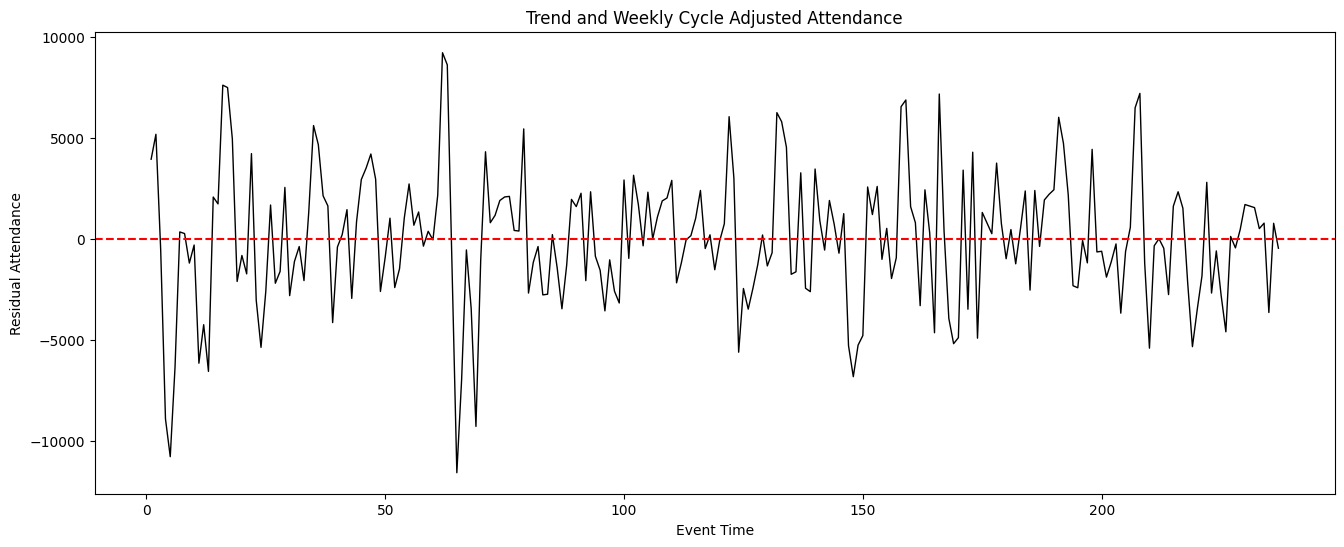

In [22]:
train_df["CycleAdjusted"] = (
    train_df["Detrended"]
    - train_df["DayOfWeek"].map(weekday_means)
)

plt.figure(figsize=(16,6))

plt.plot(
    train_df["t"],
    train_df["CycleAdjusted"],
    color="black",
    linewidth=1
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Trend and Weekly Cycle Adjusted Attendance")
plt.xlabel("Event Time")
plt.ylabel("Residual Attendance")

plt.show()

Residual Diagnostics

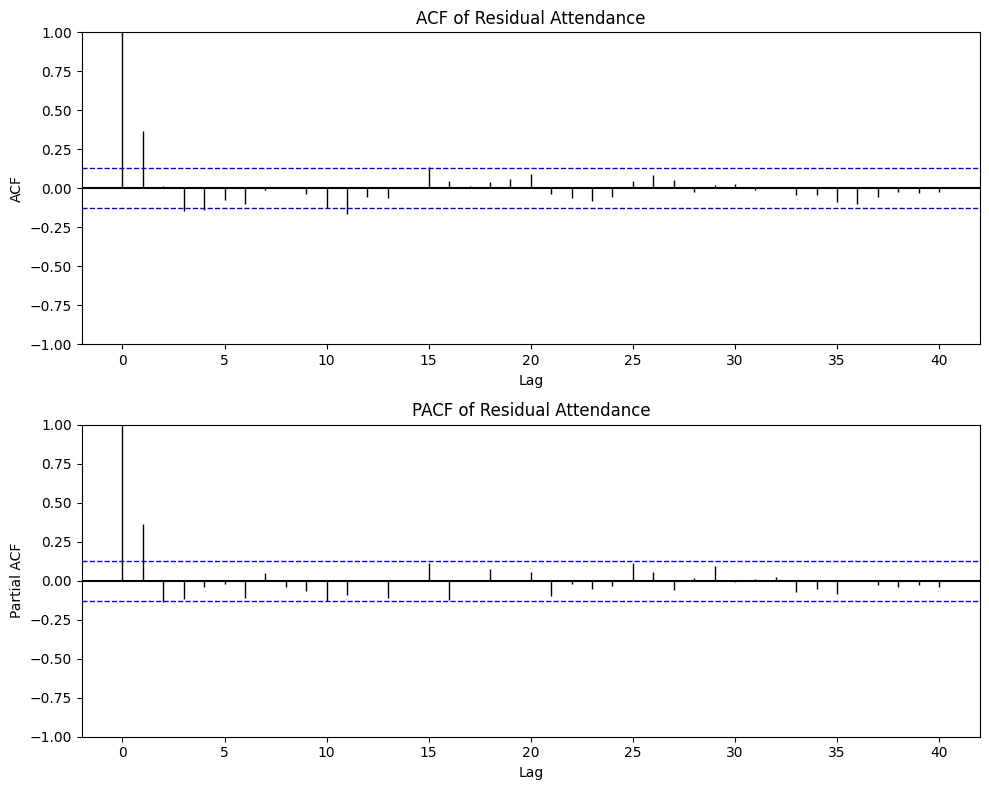

In [23]:
residual_ts = train_df["CycleAdjusted"].values

fig, axes = plt.subplots(2, 1, figsize=(10,8))

conf = 1.96 / np.sqrt(len(residual_ts))

# ACF
plot_acf(
    residual_ts,
    lags=40,
    ax=axes[0],
    alpha=None,
    color="black",
    vlines_kwargs={"colors":"black","linewidth":1},
    marker=""
)

axes[0].axhline(conf, linestyle='--', color='blue', linewidth=1)
axes[0].axhline(-conf, linestyle='--', color='blue', linewidth=1)

axes[0].set_title("ACF of Residual Attendance")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("ACF")

# PACF
plot_pacf(
    residual_ts,
    lags=40,
    method='ywm',
    ax=axes[1],
    alpha=None,
    color="black",
    vlines_kwargs={"colors":"black","linewidth":1},
    marker=""
)

axes[1].axhline(conf, linestyle='--', color='blue', linewidth=1)
axes[1].axhline(-conf, linestyle='--', color='blue', linewidth=1)

axes[1].set_title("PACF of Residual Attendance")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Partial ACF")

plt.tight_layout()
plt.show()

# Phase 3: Stochastic Modeling and Forecasting

In [24]:
# Candidate ARMA models to compare
candidate_orders = [
    (1,0,0),  # AR(1)
    (2,0,0),  # AR(2)
    (3,0,0),  # AR(3)

    (0,0,1),  # MA(1)
    (0,0,2),  # MA(2)
    (0,0,3),  # MA(3)

    (1,0,1),  # ARMA(1,1)
    (1,0,2),  # ARMA(1,2)
    (2,0,1),  # ARMA(2,1)
    (2,0,2),  # ARMA(2,2)
]

results = []

for order in candidate_orders:
    p, d, q = order

    try:
        model = ARIMA(residual_ts, order=order).fit()

        if p > 0 and q > 0:
            model_name = f"ARMA({p},{q})"
        elif p > 0:
            model_name = f"AR({p})"
        else:
            model_name = f"MA({q})"

        results.append({
            "Model": model_name,
            "Order": order,
            "AIC": model.aic,
            "BIC": model.bic,
            "LogLik": model.llf
        })

    except Exception as e:
        print(f"Model {order} failed: {e}")

model_comparison = pd.DataFrame(results)

model_comparison["AIC"] = model_comparison["AIC"].round(2)
model_comparison["BIC"] = model_comparison["BIC"].round(2)
model_comparison["LogLik"] = model_comparison["LogLik"].round(2)

model_comparison = model_comparison.sort_values("AIC").reset_index(drop=True)

model_comparison

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,Model,Order,AIC,BIC,LogLik
0,"ARMA(2,1)","(2, 0, 1)",4471.62,4488.96,-2230.81
1,"ARMA(2,2)","(2, 0, 2)",4473.28,4494.09,-2230.64
2,AR(3),"(3, 0, 0)",4481.91,4499.25,-2235.96
3,AR(2),"(2, 0, 0)",4483.35,4497.23,-2237.68
4,MA(2),"(0, 0, 2)",4484.16,4498.04,-2238.08
5,MA(1),"(0, 0, 1)",4484.60,4495.01,-2239.30
6,"ARMA(1,1)","(1, 0, 1)",4485.12,4498.99,-2238.56
7,MA(3),"(0, 0, 3)",4485.19,4502.53,-2237.59
8,AR(1),"(1, 0, 0)",4485.65,4496.05,-2239.82
9,"ARMA(1,2)","(1, 0, 2)",4485.94,4503.28,-2237.97


In [25]:
best_model = ARIMA(
    residual_ts,
    order=(2,0,1)
).fit()

print(best_model.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  237
Model:                 ARIMA(2, 0, 1)   Log Likelihood               -2230.812
Date:                Mon, 01 Jun 2026   AIC                           4471.624
Time:                        03:31:23   BIC                           4488.964
Sample:                             0   HQIC                          4478.613
                                - 237                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         98.7603     26.470      3.731      0.000      46.879     150.641
ar.L1          1.3192      0.054     24.539      0.000       1.214       1.425
ar.L2         -0.4307      0.055     -7.790      0.0

In [26]:
ma1_model = ARIMA(
    residual_ts,
    order=(0,0,1)
).fit()

print(ma1_model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  237
Model:                 ARIMA(0, 0, 1)   Log Likelihood               -2239.301
Date:                Mon, 01 Jun 2026   AIC                           4484.602
Time:                        04:28:37   BIC                           4495.006
Sample:                             0   HQIC                          4488.795
                                - 237                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.846e-07    267.298   1.06e-09      1.000    -523.895     523.895
ma.L1          0.3712      0.050      7.420      0.000       0.273       0.469
sigma2      9.193e+06   7.61e+05     12.073      0.0

In [29]:
def forecast_attendance(model, test_df, trend, weekday_means):
    forecast_steps = len(test_df)

    # 1. Forecast residual component
    residual_forecast = model.forecast(steps=forecast_steps)

    # 2. Extend trend using last LOWESS trend value
    trend_forecast = np.repeat(trend[-1], forecast_steps)

    # 3. Add weekday cycle back
    test_cycle = test_df["DayOfWeek"].map(weekday_means).values

    # 4. Reconstruct attendance forecast
    final_forecast = trend_forecast + test_cycle + residual_forecast

    return final_forecast


# Forecasts
ma1_forecast = forecast_attendance(ma1_model, test_df, trend, weekday_means)
arma21_forecast = forecast_attendance(best_model, test_df, trend, weekday_means)

# RMSE
ma1_rmse = np.sqrt(mean_squared_error(test_df["Attendance"], ma1_forecast))
arma21_rmse = np.sqrt(mean_squared_error(test_df["Attendance"], arma21_forecast))

rmse_comparison = pd.DataFrame({
    "Model": ["MA(1)", "ARMA(2,1)"],
    "AIC": [ma1_model.aic, best_model.aic],
    "BIC": [ma1_model.bic, best_model.bic],
    "RMSE": [ma1_rmse, arma21_rmse]
})

rmse_comparison[["AIC", "BIC", "RMSE"]] = rmse_comparison[["AIC", "BIC", "RMSE"]].round(2)

rmse_comparison

,Model,AIC,BIC,RMSE
0,MA(1),4484.60,4495.01,3023.78
1,"ARMA(2,1)",4471.62,4488.96,3084.73


Residual Diagnostics of Final Model
- verifying if MA(1) residuals are approximately white noise

In [ ]:
final_residuals = ma1_model.resid

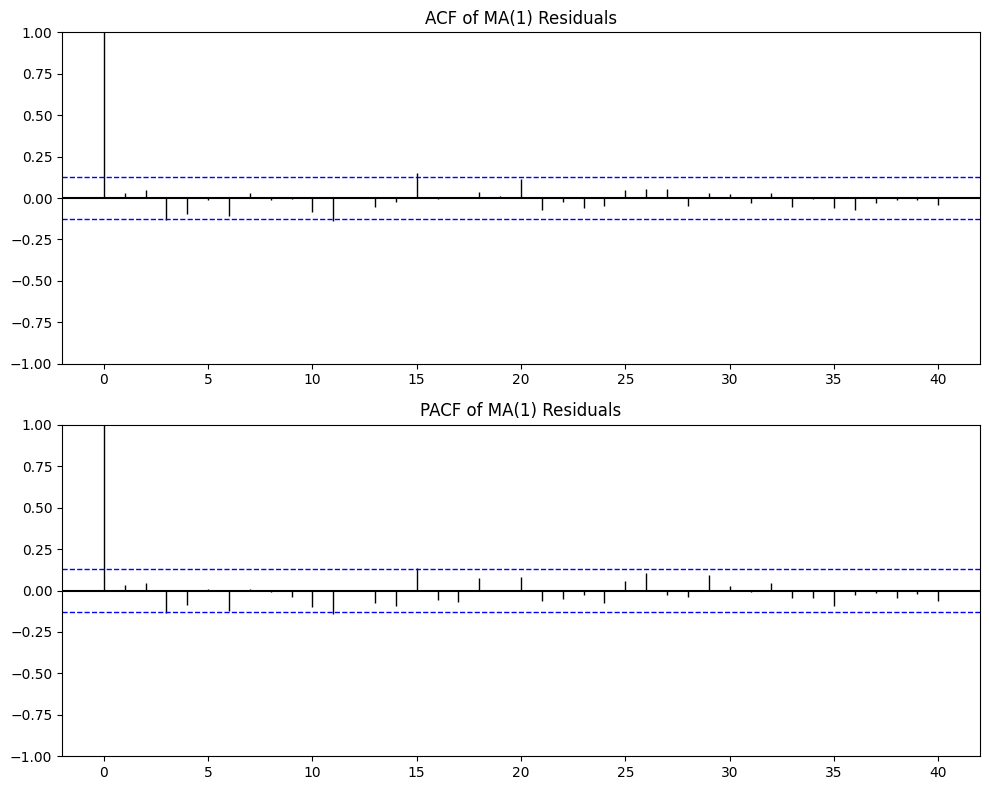

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10,8))

conf = 1.96 / np.sqrt(len(final_residuals))

# ACF
plot_acf(
    final_residuals,
    lags=40,
    ax=axes[0],
    alpha=None,
    color="black",
    vlines_kwargs={"colors":"black","linewidth":1},
    marker=""
)

axes[0].axhline(conf, linestyle='--', color='blue', linewidth=1)
axes[0].axhline(-conf, linestyle='--', color='blue', linewidth=1)

axes[0].set_title("ACF of MA(1) Residuals")

# PACF
plot_pacf(
    final_residuals,
    lags=40,
    method='ywm',
    ax=axes[1],
    alpha=None,
    color="black",
    vlines_kwargs={"colors":"black","linewidth":1},
    marker=""
)

axes[1].axhline(conf, linestyle='--', color='blue', linewidth=1)
axes[1].axhline(-conf, linestyle='--', color='blue', linewidth=1)

axes[1].set_title("PACF of MA(1) Residuals")

plt.tight_layout()
plt.show()

In [ ]:
final_residuals = ma1_model.resid

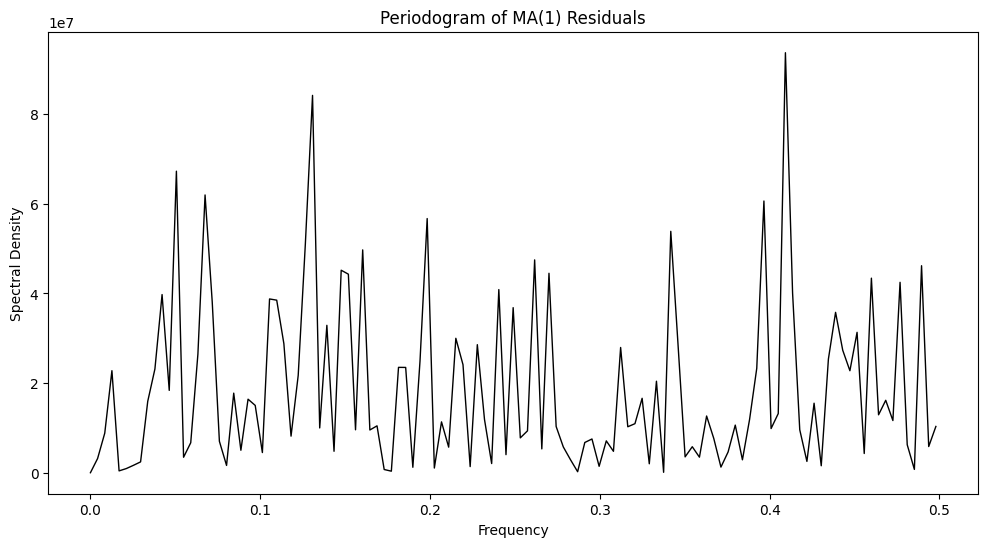

In [ ]:
freqs_resid, power_resid = periodogram(final_residuals)

plt.figure(figsize=(12,6))

plt.plot(
    freqs_resid,
    power_resid,
    color="black",
    linewidth=1
)

plt.title("Periodogram of MA(1) Residuals")
plt.xlabel("Frequency")
plt.ylabel("Spectral Density")

plt.show()

Forecasting on test set

In [ ]:
forecast_steps = len(test_df)

residual_forecast = ma1_model.forecast(
    steps=forecast_steps
)

print(residual_forecast[:5])

[-4.73375778e+02  2.84558445e-07  2.84558445e-07  2.84558445e-07
  2.84558445e-07]


In [ ]:
last_trend_value = trend[-1]

trend_forecast = np.repeat(
    last_trend_value,
    forecast_steps
)

In [ ]:
test_cycle = test_df["DayOfWeek"].map(
    weekday_means
).values

In [ ]:
final_forecast = (
    trend_forecast
    + test_cycle
    + residual_forecast
)

In [ ]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(
    mean_squared_error(
        test_df["Attendance"],
        final_forecast
    )
)

print("RMSE:", rmse)

RMSE: 3023.7763314867225


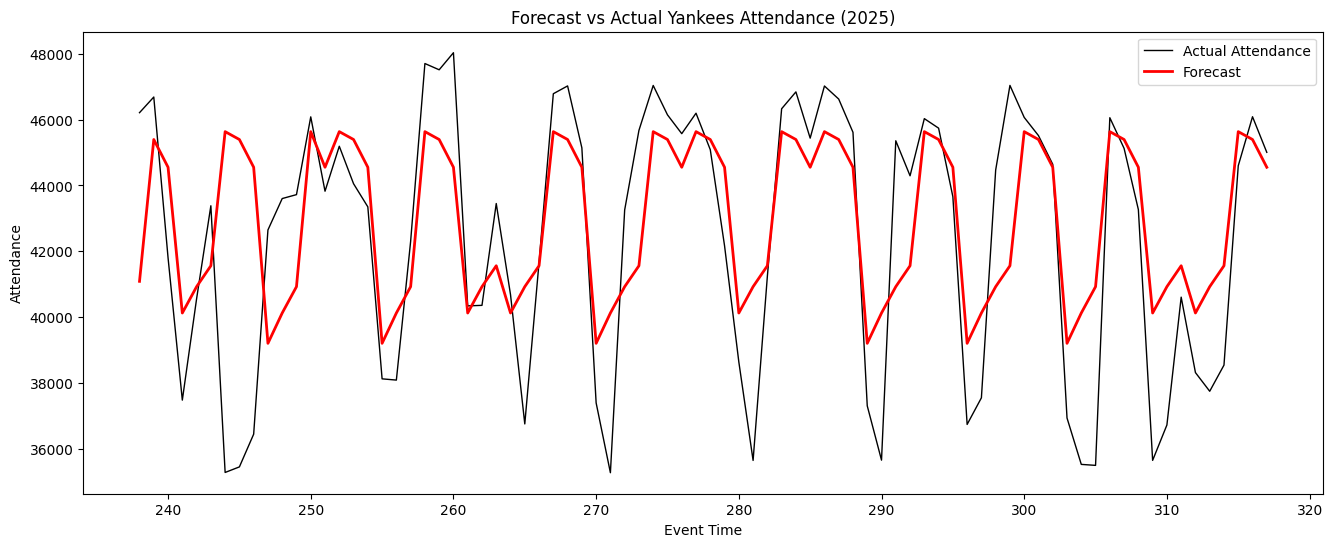

In [ ]:
plt.figure(figsize=(16,6))

# actual
plt.plot(
    test_df["t"],
    test_df["Attendance"],
    color="black",
    linewidth=1,
    label="Actual Attendance"
)

# forecast
plt.plot(
    test_df["t"],
    final_forecast,
    color="red",
    linewidth=2,
    label="Forecast"
)

plt.title("Forecast vs Actual Yankees Attendance (2025)")
plt.xlabel("Event Time")
plt.ylabel("Attendance")

plt.legend()

plt.show()

Future forecasts

In [ ]:
future_steps = 20

future_residuals = ma1_model.forecast(
    steps=future_steps
)

In [ ]:
future_days = (
    list(test_df["DayOfWeek"][-7:])
    * 3
)[:future_steps]

In [ ]:
#weekday effects
future_cycle = pd.Series(future_days).map(
    weekday_means
).values

In [ ]:
future_trend = np.repeat(
    last_trend_value,
    future_steps
)

In [ ]:
future_forecast = (
    future_trend
    + future_cycle
    + future_residuals
)

In [ ]:
future_t = np.arange(
    yankees_df["t"].max() + 1,
    yankees_df["t"].max() + future_steps + 1
)

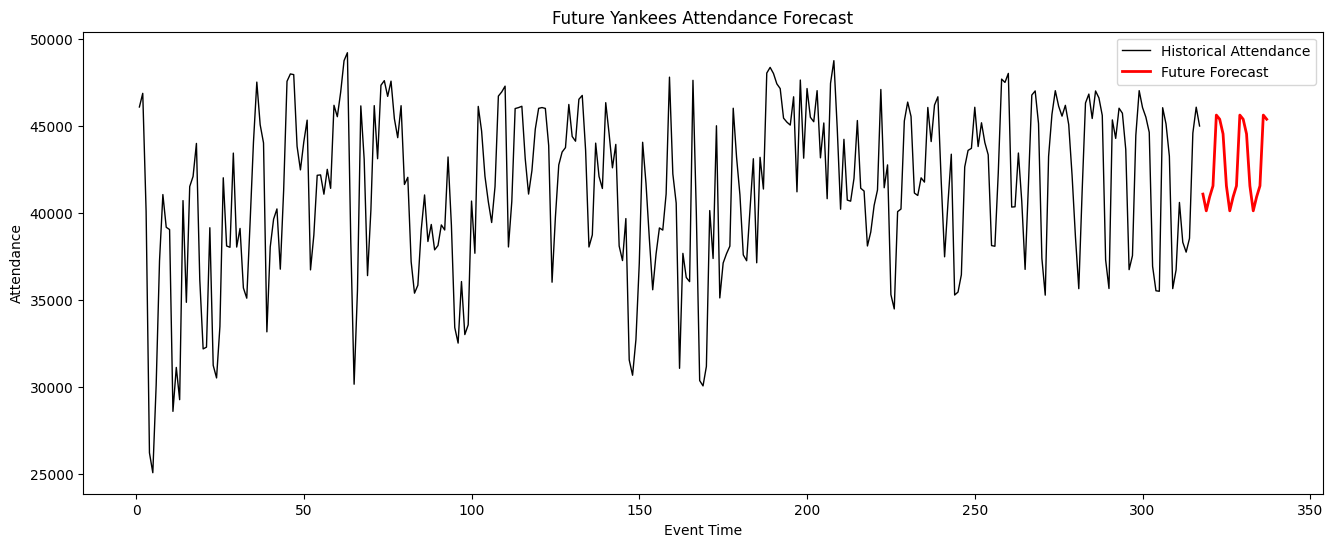

In [ ]:
plt.figure(figsize=(16,6))

# historical
plt.plot(
    yankees_df["t"],
    yankees_df["Attendance"],
    color="black",
    linewidth=1,
    label="Historical Attendance"
)

# future forecast
plt.plot(
    future_t,
    future_forecast,
    color="red",
    linewidth=2,
    label="Future Forecast"
)

plt.title("Future Yankees Attendance Forecast")
plt.xlabel("Event Time")
plt.ylabel("Attendance")

plt.legend()

plt.show()